# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [149]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr

### Cargar Dataset

In [150]:
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [151]:
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


In [152]:
df.dtypes

id_cliente                    object
edad                         float64
nivel_ingreso                float64
visitas_mes                    int64
compras_mes                    int64
gasto_publicidad_dirigida    float64
satisfaccion                 float64
miembro_premium                int64
abandono                       int64
tipo_dispositivo              object
region                        object
ingreso_anual                float64
dtype: object

## Sección 2 - Preparar datos y documentar supuestos

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna edad aparece como float64 debido a la presencia de decimales o diseño inicial.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`
  
Estas variables están correctamente definidas y no requieren transformación adicional.

In [153]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype('int64')

# Verificar tipos de datos
df.dtypes

id_cliente                    object
edad                           int64
nivel_ingreso                float64
visitas_mes                    int64
compras_mes                    int64
gasto_publicidad_dirigida    float64
satisfaccion                 float64
miembro_premium                int64
abandono                       int64
tipo_dispositivo              object
region                        object
ingreso_anual                float64
dtype: object

In [154]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [155]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad`: los datos muestran una distribución que va desde un valor mínimo de 18 hasta un máximo de 75 años, con un valor central (mediana/percentil 50) ubicado exactamente en los 38 años.
- `nivel_ingreso`: registra un valor mínimo estimado de 8,000 y un valor máximo de 74,790.84, situándose el 50% de las observaciones por debajo de los 30,023.74.
-`visitas_mes`: presenta un rango que va desde 1 visita mensual hasta un máximo de 25, con una mediana situada en las 10 visitas al mes.
- `compras_mes`: El percentil 75 se ubica en 2 compras mensuales, lo que indica que el 75% de la base de clientes realiza un volumen muy bajo de transacciones (dos o menos compras al mes). Sin embargo, el valor máximo llega a 8 compras. Esta disparidad revela que la gran mayoría de los usuarios tienen una frecuencia de compra menos efectiva, mientras que existe un grupo minoritario altamente activo que concentra una mayor interacción de transacciones.
- `gasto_publicidad_dirigida`: registra valores desde 0 hasta un máximo de 75.51, con una mediana (percentil 50) de 19.73.
- `satisfacción`: oscila en una escala numérica desde un mínimo de 1.0 hasta un máximo de 5.0, con un valor mediano de 3.6.
- `ingreso_anual`: Tanto el valor mínimo como el percentil 25 se encuentran en 0, lo que demuestra que al menos una cuarta parte de los clientes registrados en la plataforma no generan ningún tipo de ingreso económico para NovaRetail+. Esto pone de relieve la presencia de un segmento considerable de usuarios inactivos o de bajo valor monetario dentro del volumen total analizado.

#### Explorar variables binarias

In [156]:
# Verificar que cada columna tenga únicamente dos valores posibles
df["miembro_premium"].unique()

array([0, 1])

In [157]:
# Verificar que cada columna tenga únicamente dos valores posibles
df["abandono"].unique()

array([0, 1])

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium`> Los datos se limitan estrictamente a los valores [0 y 1], lo que confirma que la base está limpia y dividida con precisión entre usuarios estándar y suscriptores premium. Esto permitirá comparar de forma directa si los miembros de pago generan un impacto diferencial en los ingresos de la empresa.
- `abandono`: Los valores únicos también se reducen limpiamente a [0 y 1], validando el registro del estatus de los usuarios. Este indicador muestra quiénes continúan activos y quiénes dejaron la plataforma, listo para analizar cómo la deserción impacta el desempeño económico general

#### Explorar variables categóricas

In [158]:
# Verificar el número de valores únicos por variable categórica
df[["id_cliente","tipo_dispositivo","region"]].nunique()

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

In [159]:
# Explorar variables categóricas y cómo se distribuyen
df["tipo_dispositivo"].value_counts()

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

In [160]:
# Explorar variables categóricas y cómo se distribuyen
df["region"].value_counts()

norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas
 
- `id_cliente`: Registra exactamente 15,000 valores únicos, lo que confirma que cada fila representa a un cliente completamente distinto y que no existen duplicados en las identificaciones principales de la base de datos.  
- `tipo_dispositivo`: Se divide en 3 categorías, donde los dispositivos móviles concentran con diferencia la mayor parte de la base (9,818 usuarios), superando ampliamente a escritorio (3,720) y tablet (1,462). Esto evidencia que el canal móvil es el medio principal de interacción en la plataforma.
- `región`: Se distribuye en 4 zonas geográficas con una participación relativamente equilibrada, destacando la región norte con el mayor volumen (4,395 usuarios) y la región este con el menor (3,069), lo que permite dimensionar la presencia territorial de NovaRetail+

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

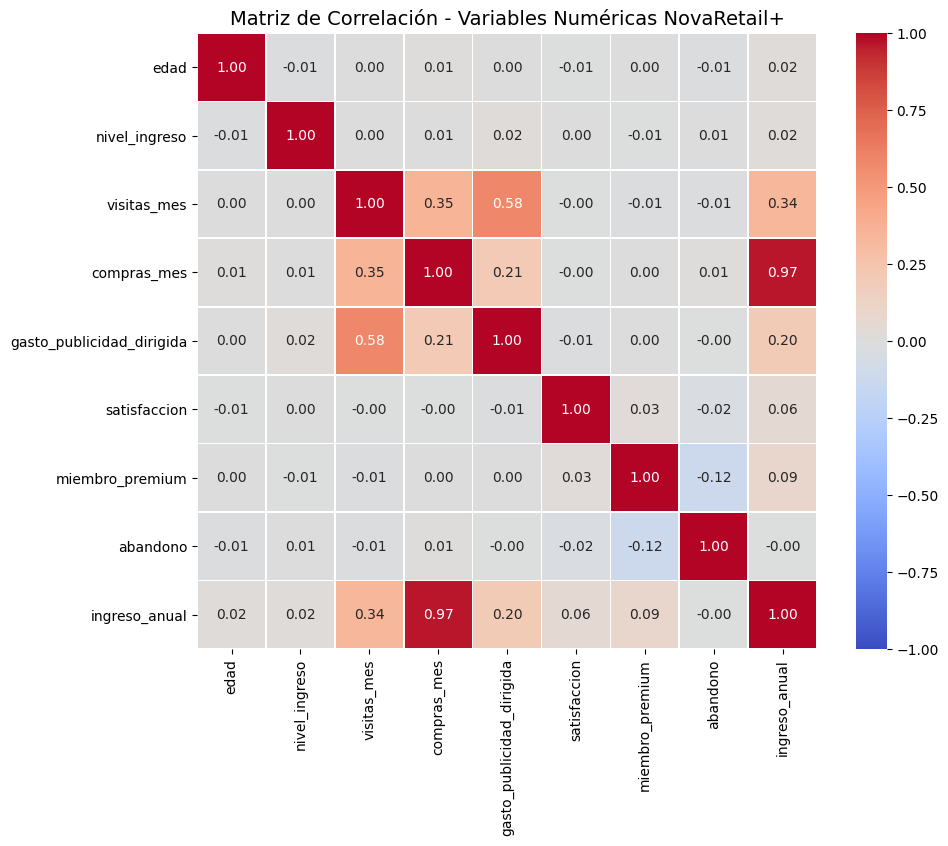

In [161]:
# Visualizar la matriz de correlación para identificar relaciones
matriz_correlacion = df.select_dtypes(include=['number']).corr()

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Generar el heatmap con Seaborn
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

# Título y visualización
plt.title('Matriz de Correlación - Variables Numéricas NovaRetail+', fontsize=14)
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- La mayoría de las variables presentan correlaciones cercanas a 0, lo que indica ausencia de relaciones lineales relevantes entre gran parte de las variables analizadas.
- Se observa una correlación positiva moderada entre visitas_mes y compras_mes (0.35). Esta asociación resulta relevante porque ambas variables representan diferentes etapas del comportamiento del cliente y podrían analizarse conjuntamente en exploraciones posteriores.
- Se observa una correlación positiva moderada entre visitas_mes y gasto_publicidad_dirigida (0.58) la segunda más fuerte después de ingreso_anual y compras_mes. Dado que ambas variables están relacionadas con actividades de interacción comercial, esta relación merece una revisión más detallada en análisis posteriores.
- La correlación más alta de la matriz corresponde a compras_mes e ingreso_anual (0.97), mostrando una asociación lineal muy fuerte entre ambas variables. Este resultado sugiere que conviene profundizar en esta relación para comprender mejor su comportamiento dentro del conjunto de datos.

Observaciones respecto a `ingreso_anual`  
- Presenta una correlación positiva muy alta con compras_mes (0.97). Debido a la magnitud de esta asociación, esta relación constituye uno de los principales focos de análisis para etapas posteriores.
- Presenta una correlación positiva moderada con visitas_mes (0.34). Aunque la intensidad es considerablemente menor que la observada con compras_mes, la relación resulta suficiente para justificar una exploración adicional.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

 No se incluye scatterplot general por redundancia con el heatmap, ya que, La matriz de correlación (heatmap) ya cumple la función de evaluar todas las variables numéricas de forma rápida y conjunta El scatterplot pierde su propósito analítico si se usa de manera masiva e indiscriminada.

### Scatterplot para pares clave

In [162]:
# Visualizar pares de variables con relaciones moderadas o fuertes


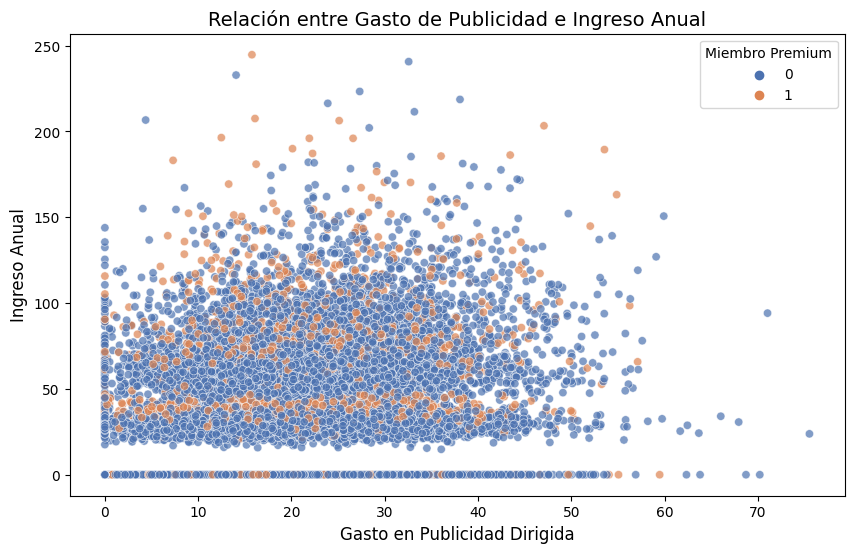

In [163]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df, 
    x='gasto_publicidad_dirigida', 
    y='ingreso_anual', 
    hue='miembro_premium',
    alpha=0.7,             # Transparencia para ver la densidad de puntos
    palette='deep'
)

plt.title('Relación entre Gasto de Publicidad e Ingreso Anual', fontsize=14)
plt.xlabel('Gasto en Publicidad Dirigida', fontsize=12)
plt.ylabel('Ingreso Anual', fontsize=12)

plt.legend(title='Miembro Premium')
plt.show()




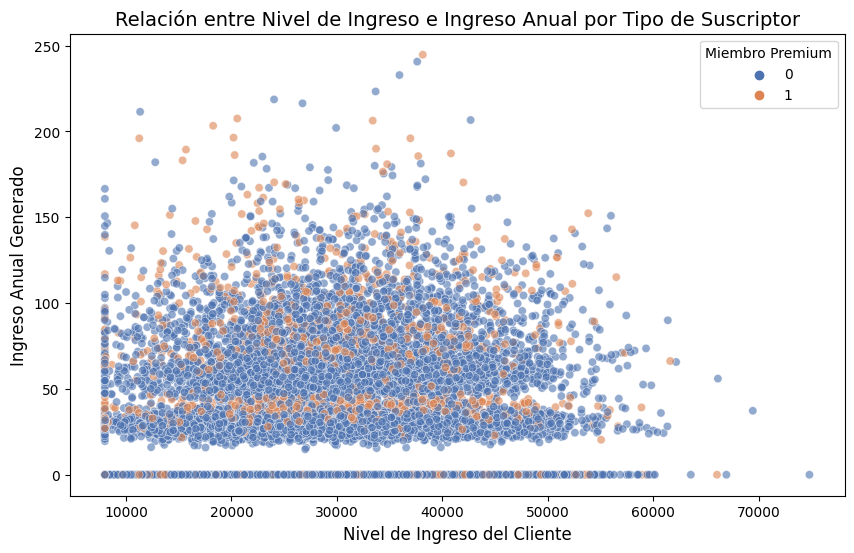

In [164]:
plt.figure(figsize=(10, 6))

# Scatterplot focalizado
sns.scatterplot(
    data=df, 
    x='nivel_ingreso', 
    y='ingreso_anual', 
    hue='miembro_premium', 
    alpha=0.6,
    palette='deep'
)

plt.title('Relación entre Nivel de Ingreso e Ingreso Anual por Tipo de Suscriptor', fontsize=14)
plt.xlabel('Nivel de Ingreso del Cliente', fontsize=12)
plt.ylabel('Ingreso Anual Generado', fontsize=12)
plt.legend(title='Miembro Premium')
plt.show()


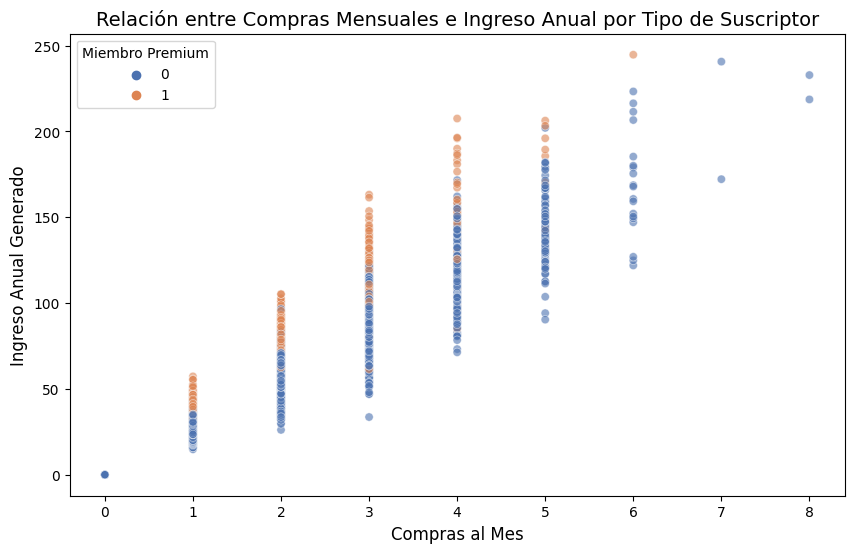

In [165]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='compras_mes', 
    y='ingreso_anual', 
    hue='miembro_premium', 
    alpha=0.6,
    palette='deep'
)

plt.title('Relación entre Compras Mensuales e Ingreso Anual por Tipo de Suscriptor', fontsize=14)
plt.xlabel('Compras al Mes', fontsize=12)
plt.ylabel('Ingreso Anual Generado', fontsize=12)

plt.legend(title='Miembro Premium')
plt.show()


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**Análisis de la relación entre gasto_publicidad_dirigida e ingreso_anual**

- Dirección: Se observa una tendencia positiva débil. A medida que aumenta el gasto en publicidad dirigida, aparecen algunos valores más altos de ingreso anual; sin embargo, la tendencia no es claramente pronunciada.
- Dispersión: La dispersión es alta. Para niveles similares de gasto publicitario se observan ingresos anuales muy variados, lo que genera una nube de puntos ampliamente distribuida.
- Outliers: Se identifican algunos casos aislados con ingresos anuales considerablemente superiores al resto (por encima de 200) y algunos registros con niveles de gasto publicitario notablemente más altos que la mayoría de las observaciones.
- Posible colinealidad: No se observa un patrón visual que sugiera colinealidad fuerte entre las variables. Esto es consistente con la correlación baja observada previamente en el heatmap (r = 0.20).
- Segmentación por tipo de suscriptor: Los clientes premium y no premium presentan un alto grado de superposición visual, sin agrupaciones claramente diferenciadas en el gráfico.
- Los patrones identificados son descriptivos y deben interpretarse únicamente como asociaciones observadas en la visualización. La correlación y la distribución visual no permiten establecer relaciones causales.

**Análisis de la relación entre Nivel de Ingreso e Ingreso Anual por Tipo de Suscriptor**
- Dirección: No se observa una dirección clara (ni positiva ni negativa). La nube de puntos se distribuye de manera relativamente uniforme a lo largo del eje de nivel de ingreso.
- Dispersión: La dispersión es alta. Para valores similares de nivel de ingreso se observan ingresos anuales muy diferentes.
- Outliers: Se identifican algunos registros aislados con ingresos anuales elevados y algunos casos situados en los extremos superiores del nivel de ingreso del cliente.
- Posible colinealidad: No se observan evidencias visuales de colinealidad. La ausencia de una forma lineal definida es consistente con la correlación prácticamente nula observada en el heatmap (r = 0.02).
- Segmentación por tipo de suscriptor: Los clientes premium y no premium muestran una fuerte superposición a lo largo de toda la nube de puntos, sin una separación visual evidente.
- Los hallazgos visuales son coherentes con los resultados obtenidos previamente en la matriz de correlación.

**Análisis de la relación entre Compras Mensuales e Ingreso Anual por Tipo de Suscriptor**
- Dirección: Se observa una tendencia positiva muy marcada. A medida que aumenta el número de compras mensuales, los valores de ingreso anual tienden a incrementarse de forma consistente.
- Dispersión: La dispersión es baja a moderada. Aunque existe variabilidad dentro de cada nivel de compras, los puntos mantienen un patrón ascendente bien definido y concentrado.
- Outliers: Se identifican algunos registros con ingresos anuales significativamente superiores al resto, especialmente para valores de compras entre 4 y 8 al mes. Sin embargo, estos casos siguen la dirección general de la nube y no alteran el patrón observado.
- Posible colinealidad: Se observa una fuerte alineación entre ambas variables, consistente con la alta correlación observada en el heatmap (r = 0.97). Este comportamiento sugiere una posible colinealidad si ambas variables fueran utilizadas conjuntamente en modelos predictivos.
- Segmentación por tipo de suscriptor: Los clientes premium y no premium presentan una amplia superposición a lo largo del gráfico. No obstante, los clientes premium parecen concentrar una mayor proporción de observaciones en los niveles más altos de ingreso anual para un mismo número de compras, aunque esta diferencia no genera grupos claramente separados.



## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [166]:
# Calcular correlación entre variables relevantes (Pearson)
pares_variables = [
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('compras_mes', 'ingreso_anual'),
    ('nivel_ingreso', 'ingreso_anual')  # Par agregado
]

# Calcular la correlación de Pearson para cada par
for var1, var2 in pares_variables:
    correlacion = df[[var1, var2]].corr(method='pearson').iloc[0, 1]
    print(f"Correlación de Pearson entre {var1} y {var2}: {correlacion:.4f}")


Correlación de Pearson entre gasto_publicidad_dirigida y ingreso_anual: 0.1975
Correlación de Pearson entre compras_mes y ingreso_anual: 0.9671
Correlación de Pearson entre nivel_ingreso y ingreso_anual: 0.0174


In [167]:
# Calcular correlación entre variables relevantes (Spearman)
pares_variables = [
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('compras_mes', 'ingreso_anual'),
    ('nivel_ingreso', 'ingreso_anual')
]

# Calcular la correlación de Spearman para cada par
for var1, var2 in pares_variables:
    correlacion_spearman = df[[var1, var2]].corr(method='spearman').iloc[0, 1]
    print(f"Correlación de Spearman entre {var1} y {var2}: {correlacion_spearman:.4f}")

Correlación de Spearman entre gasto_publicidad_dirigida y ingreso_anual: 0.1850
Correlación de Spearman entre compras_mes y ingreso_anual: 0.9675
Correlación de Spearman entre nivel_ingreso y ingreso_anual: 0.0250


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**Análisis de correlación entre gasto_publicidad_dirigida e ingreso_anual**

- Dirección: Positiva.
- Magnitud: Débil. Tanto Pearson (0.1975) como Spearman (0.1850) muestran una asociación positiva de baja intensidad.
- Consistencia entre métodos: La similitud entre ambos coeficientes sugiere que la asociación observada es estable y no depende de una forma estrictamente lineal.
- Posible colinealidad: No se observan indicios de colinealidad relevante. Los coeficientes se encuentran muy por debajo de los niveles normalmente asociados a posibles problemas de colinealidad.

**Análisis de correlación entre Compras Mensuales e Ingreso Anual**
- Dirección: Positiva.
- Magnitud: Muy fuerte. Pearson (0.9671) y Spearman (0.9675) indican una asociación extremadamente alta entre ambas variables.
- Consistencia entre métodos: Los valores son prácticamente idénticos, lo que sugiere que la relación observada es muy robusta tanto en términos lineales como monotónicos.
- Posible colinealidad: Sí existe evidencia de posible colinealidad debido a la magnitud extremadamente alta de la correlación. Si ambas variables fueran incluidas simultáneamente en modelos predictivos, sería recomendable evaluar formalmente la multicolinealidad.

**Análisis de correlación entre Nivel de Ingreso e Ingreso Anual**
- Dirección: Positiva.
- Magnitud: Prácticamente nula. Pearson (0.0174) y Spearman (0.0250) se encuentran muy próximos a cero.
- Consistencia entre métodos: Ambos coeficientes confirman la ausencia de una asociación relevante entre las variables.
- Posible colinealidad: No existe evidencia de colinealidad. Los coeficientes son demasiado bajos para sugerir dependencia entre las variables.

### Punto-biserial

In [168]:
# Calcular correlación entre variables relevantes
pares_punto_biserial = [
    ('miembro_premium', 'ingreso_anual'),
    ('miembro_premium', 'compras_mes'),
    ('abandono', 'gasto_publicidad_dirigida')
]

# Calcular la correlación punto biserial para cada par
for bin_var, cont_var in pares_punto_biserial:
    # Asegurarnos de eliminar nulos
    df_clean = df.dropna(subset=[bin_var, cont_var])
    
    # Calcular el coeficiente punto biserial y su valor p
    resultado = pointbiserialr(df_clean[bin_var], df_clean[cont_var])
    
    print(f"Punto Biserial entre {bin_var} (binaria) y {cont_var} (continua):")
    print(f"  Coeficiente: {resultado.statistic:.4f}")
    print(f"  Valor p (p-value): {resultado.pvalue:.4e}\n")

Punto Biserial entre miembro_premium (binaria) y ingreso_anual (continua):
  Coeficiente: 0.0931
  Valor p (p-value): 3.0943e-30

Punto Biserial entre miembro_premium (binaria) y compras_mes (continua):
  Coeficiente: 0.0034
  Valor p (p-value): 6.7440e-01

Punto Biserial entre abandono (binaria) y gasto_publicidad_dirigida (continua):
  Coeficiente: -0.0046
  Valor p (p-value): 5.7439e-01



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**Correlación punto biserial entre Miembro Premium e Ingreso Anual**
- Dirección: Positiva.
- Magnitud: Baja (r = 0.0931).
- Significancia estadística: El valor p es extremadamente bajo (p ≈ 3.09 × 10-30), muy inferior al umbral común de 0.05.
- La asociación observada es débil en términos prácticos debido a la baja magnitud del coeficiente.
- Sin embargo, la evidencia estadística indica que esta asociación difícilmente puede atribuirse al azar dentro de la muestra analizada.
- Existe evidencia estadística de una relación positiva entre ambas variables, aunque el tamaño del efecto es pequeño.

**Correlación punto biserial entre Miembro Premium y Compras Mensuales**
- Dirección: Positiva.
- Magnitud: Prácticamente nula (r = 0.0034).
- Significancia estadística: El valor p es elevado (p = 0.6744), muy superior a 0.05.
- El coeficiente es extremadamente cercano a cero.
- No existe evidencia estadística suficiente para afirmar que haya una asociación entre ambas variables.
- La pequeña diferencia observada en la muestra es compatible con fluctuaciones aleatorias de los datos.

**Correlación punto biserial entre Abandono y Gasto en Publicidad Dirigida**
- Dirección: Negativa.
- Magnitud: Prácticamente nula (r = -0.0046).
- Significancia estadística: El valor p es elevado (p = 0.5744).
- La relación observada es prácticamente inexistente.
- El resultado no es estadísticamente significativo.
- No existe evidencia estadística suficiente para sostener una asociación entre las variables analizadas.

### V de Cramér

In [169]:
# Función para calcular V de Cramér
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

def cramers_v_con_pvalue(confusion_matrix):
    """Calcula el coeficiente V de Cramér y el p-value de la prueba chi-cuadrada"""
    # 1. Obtener estadístico chi2, p-value, grados de libertad y frecuencias esperadas
    chi2, p_value, dof, ex = chi2_contingency(confusion_matrix)
    
    # 2. Obtener el número total de observaciones (n) y dimensiones
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    
    # 3. Calcular V de Cramér
    v_cramer = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    
    return v_cramer, p_value

In [170]:

# Aplicar V de Cramér en variables relevantes
pares_categoricos_reales = [
    ('tipo_dispositivo', 'region'),
    ('tipo_dispositivo', 'abandono'),
    ('region', 'abandono')
]

# Ejecutar y mostrar los resultados con su respectivo p-value
for cat1, cat2 in pares_categoricos_reales:
    if cat1 in df.columns and cat2 in df.columns:
        tabla_contingencia = pd.crosstab(df[cat1], df[cat2])
        v_cramer, p_val = cramers_v_con_pvalue(tabla_contingencia)
        
        print(f"V de Cramér entre {cat1} y {cat2}:")
        print(f"  Coeficiente: {v_cramer:.4f}")
        print(f"  Valor p (p-value): {p_val:.4e}\n")
    else:
        print(f"Una o ambas variables ({cat1}, {cat2}) no se encuentran en el DataFrame.")

V de Cramér entre tipo_dispositivo y region:
  Coeficiente: 0.0124
  Valor p (p-value): 5.9648e-01

V de Cramér entre tipo_dispositivo y abandono:
  Coeficiente: 0.0072
  Valor p (p-value): 6.7456e-01

V de Cramér entre region y abandono:
  Coeficiente: 0.0154
  Valor p (p-value): 3.1165e-01



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

**Análisis de Tipo de Dispositivo y Región**
- Magnitud: Asociación prácticamente nula (V = 0.0124).
- Significancia estadística: El valor p (0.5965) es considerablemente superior a 0.05.
- No existe evidencia estadística suficiente para afirmar que el tipo de dispositivo y la región estén asociados.
- Segmentar estrategias digitales o de experiencia de usuario únicamente por región probablemente aportaría poco valor desde
- la perspectiva del tipo de dispositivo utilizado.
- No se identifican patrones regionales relevantes de adopción de dispositivos dentro de los datos analizados.

**Análisis de Tipo de Dispositivo vs Abandono**
- Magnitud: Asociación prácticamente nula (V = 0.0072).
- Significancia estadística: El valor p (0.6746) es superior a 0.05.
- No existe evidencia estadística de una relación entre el dispositivo utilizado y el abandono.
- El tipo de dispositivo no emerge como una variable prioritaria para explicar el abandono dentro de este análisis exploratorio.
- No hay evidencia que justifique focalizar estrategias de retención exclusivamente según el dispositivo utilizado por el cliente.

**Análisis de Región vs Abandono**
- Magnitud: Asociación prácticamente nula (V = 0.0154).
- Significancia estadística: El valor p (0.3117) es superior a 0.05.
- Aunque presenta el mayor coeficiente de los tres pares analizados, la magnitud sigue siendo extremadamente baja y no significativa.
- La ubicación geográfica, al menos bajo la variable región definida en este conjunto de datos, no parece ser un factor diferenciador importante del abandono.
- Las estrategias de retención probablemente deberían orientarse hacia otras variables con asociaciones más fuertes identificadas previamente en el análisis.


## Sección 5 - Interpretación de resultados para el negocio


Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio


**Hallazgo 1**
- `Evidencia visual`: Gráfico de dispersión entre compras_mes e ingreso_anual con un patrón ascendente claramente definido y baja dispersión relativa.
- `Evidencia numérica`: Correlación de Pearson = 0,9671 y Spearman = 0,9675 entre compras_mes e ingreso_anual.

*Interpretación:*
- Existe una asociación positiva muy fuerte entre el número de compras mensuales y el ingreso anual. Los clientes con mayores ingresos tienden a registrar una mayor frecuencia de compras.
- No podemos concluir que un mayor ingreso anual sea la causa directa de un mayor número de compras, ni que incrementar uno provoque automáticamente cambios en el otro.
- El ingreso anual puede ser una variable útil para segmentar clientes y diseñar estrategias comerciales diferenciadas orientadas a frecuencia de compra y valor potencial.


**Hallazgo 2**

- `Evidencia visual`: El scatterplot entre gasto_publicidad_dirigida e ingreso_anual muestra una tendencia positiva débil, con alta dispersión y algunos valores extremos.
- `Evidencia numérica`: Correlación de Pearson = 0,1975 y Spearman = 0,1850 entre gasto_publicidad_dirigida e ingreso_anual.

*Interpretación:*

- Se observa una asociación positiva, pero débil, entre el gasto en publicidad dirigida y el ingreso anual. Aunque ambos indicadores tienden a moverse en la misma dirección, la relación es limitada y presenta una variabilidad considerable.
- No podemos afirmar que la inversión publicitaria dirigida genere incrementos en el ingreso anual ni que exista una relación causal entre ambas variables.
- La publicidad dirigida podría ser un factor complementario dentro de una estrategia más amplia, pero los resultados sugieren que existen otras variables con mayor capacidad explicativa sobre el desempeño económico de los clientes.

**Hallazgo 3**

- `Evidencia visual`: Los clientes premium y no premium presentan una amplia superposición en los gráficos analizados, sin separación visual clara entre grupos.
- `Evidencia numérica`: Correlación punto-biserial = 0,0931 entre miembro_premium e ingreso_anual. Adicionalmente, la correlación entre miembro_premium y compras_mes fue 0,0034, prácticamente nula.

*Interpretación:*

- La membresía premium presenta una asociación positiva muy débil con el ingreso anual y prácticamente ninguna asociación con la cantidad de compras realizadas.
- No podemos concluir que convertirse en cliente premium aumente los ingresos o la frecuencia de compra de un cliente.
- Conviene revisar el valor diferencial de la propuesta premium y analizar segmentos específicos donde el programa pueda generar mayor impacto, en lugar de asumir beneficios homogéneos para toda la base de clientes

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Las relaciones identificadas corresponden a asociaciones estadísticas y correlación no implica causalidad.
- Pueden existir variables no medidas que expliquen parcial o totalmente las asociaciones observadas.
- Algunas relaciones presentan alta dispersión, lo que limita su capacidad predictiva de forma aislada.
- Los resultados reflejan patrones agregados y podrían ocultar comportamientos diferentes entre subgrupos de clientes.
- Las asociaciones débiles o nulas no necesariamente implican ausencia total de relación en segmentos específicos.

### **Próximos pasos** 

- Realizar segmentaciones por nivel de ingreso, antigüedad, región, dispositivo o comportamiento de compra para identificar patrones más específicos.
- Analizar posibles interacciones entre variables mediante modelos multivariantes.
- Evaluar el desempeño del programa premium en distintos perfiles de clientes para detectar segmentos de mayor valor.
- Diseñar experimentos controlados o pruebas A/B que permitan validar hipótesis causales relacionadas con campañas publicitarias, promociones o beneficios de membresía.
- Incorporar nuevas variables de comportamiento, fidelización y experiencia de cliente para reducir el riesgo de sesgo por variables omitidas.
- Complementar el análisis correlacional con modelos predictivos y métricas de negocio orientadas a captación, retención y valor del cliente.